In [1]:

print("Họ tên: NguyenDucTinh")
print("Mã số sinh viên: 6451071077")

# Linear algebra
import numpy as np

# Data processing
import pandas as pd

# Data visualization
import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style

# Đọc dữ liệu từ file bank-full(1).csv
df = pd.read_csv(
    "bank-full.csv",
    sep=";",
    dtype={
        "age": np.int64,
        "balance": np.int64,
        "day": np.int64,
        "duration": np.int64,
        "campaign": np.int64,
        "pdays": np.int64,
        "previous": np.int64
    }
)



Họ tên: NguyenDucTinh
Mã số sinh viên: 6451071077


In [2]:
print("Họ tên: NguyenDucTinh")
print("Mã số sinh viên: 6451071077")


# Chuyển đổi logic tạo biến mới dựa trên số lần liên lạc trước đó (previous) và số ngày từ lần liên lạc trước (pdays)
for dataset in [df]:
    dataset['prior_contacts'] = dataset['previous'] + (dataset['pdays'] > 0).astype(int)
    dataset.loc[dataset['prior_contacts'] > 0, 'has_prior'] = 0
    dataset.loc[dataset['prior_contacts'] == 0, 'has_prior'] = 1
    dataset['has_prior'] = dataset['has_prior'].astype(int)

# Thống kê số lượng các giá trị của biến mới tạo
print(df['has_prior'].value_counts())

Họ tên: NguyenDucTinh
Mã số sinh viên: 6451071077
has_prior
1    36954
0     8257
Name: count, dtype: int64


Họ tên: NguyenDucTinh
Mã số sinh viên: 6451071077


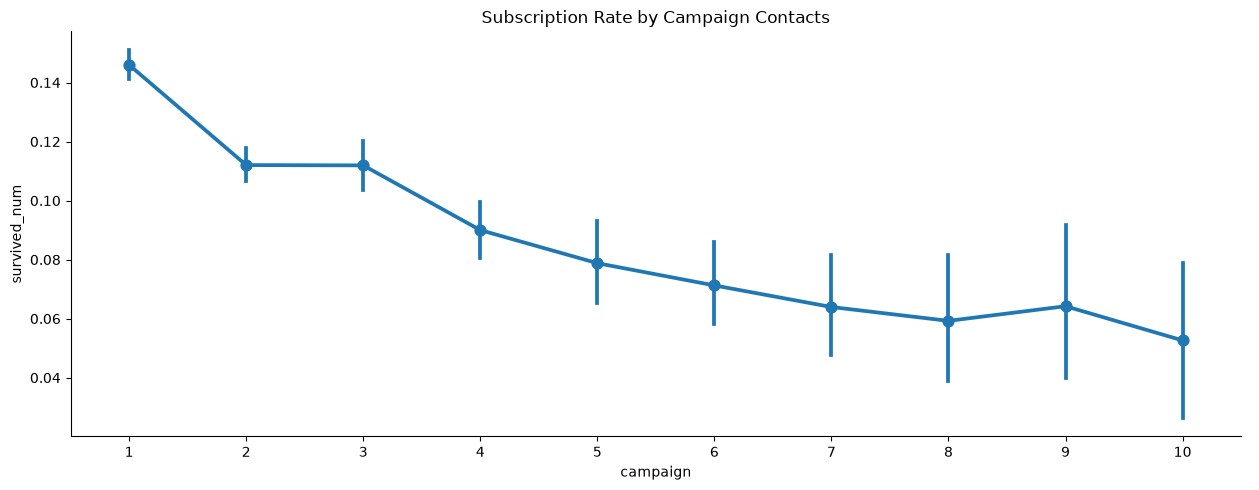

In [3]:
print("Họ tên: NguyenDucTinh")
print("Mã số sinh viên: 6451071077")

# Chuyển đổi cột mục tiêu 'y' thành dạng số (1 cho 'yes', 0 cho 'no')
df['survived_num'] = df['y'].apply(lambda x: 1 if x == 'yes' else 0)

# Vẽ biểu đồ catplot dạng điểm (pointplot) thể hiện tỷ lệ đăng ký theo số lần liên lạc trong chiến dịch (campaign)
# Giới hạn campaign <= 10 để biểu đồ rõ ràng và dễ quan sát
axes = sns.catplot(
    x='campaign',
    y='survived_num',
    data=df[df['campaign'] <= 10],
    aspect=2.5,
    kind='point'
)

plt.title('Subscription Rate by Campaign Contacts')
plt.tight_layout()
plt.show()